In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:

PROJECT_ROOT = Path.cwd().parent

CLEANED_DATA_PATH = (
    PROJECT_ROOT / "data" / "cleaned" / "nyc_311_cleaned.csv"
)

FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [3]:

df = pd.read_csv(
    CLEANED_DATA_PATH,
    dtype={
        "unique_key": "string",
        "incident_zip": "Int64",
        "council_district": "Int64",
        "bbl": "Int64",
    },
    parse_dates=[
        "created_date",
        "closed_date",
        "resolution_action_updated_date",
    ],
)


In [4]:
print(f"Dataset shape: {df.shape}")

Dataset shape: (10000, 35)


In [5]:
df.head()

,unique_key,created_date,closed_date,agency,agency_name,complaint_type,descriptor,descriptor_2,location_type,incident_zip,...,bbl,borough,x_coordinate_state_plane,y_coordinate_state_plane,open_data_channel_type,park_facility_name,park_borough,latitude,longitude,location
0,71177549,2026-11-19 02:06:04,NaT,NYPD,NEW YORK CITY POLICE DEPARTMENT,NOISE - STREET/SIDEWALK,LOUD MUSIC/PARTY,NaN,STREET/SIDEWALK,<NA>,...,<NA>,UNSPECIFIED,1003984.0,188194.0,MOBILE,Unspecified,UNSPECIFIED,40.683204,-73.928848,POINT (-73.92884819405 40.683203826171)
1,71174557,2026-11-19 02:06:02,NaT,NYPD,NEW YORK CITY POLICE DEPARTMENT,NOISE - RESIDENTIAL,LOUD MUSIC/PARTY,NaN,RESIDENTIAL BUILDING/HOUSE,11221,...,3033880001,BROOKLYN,1007618.0,189996.0,PHONE,Unspecified,BROOKLYN,40.688141,-73.915739,POINT (-73.91573940478 40.688141053869)
2,71170180,2026-11-19 02:04:42,NaT,NYPD,NEW YORK CITY POLICE DEPARTMENT,ILLEGAL PARKING,BLOCKED HYDRANT,NaN,STREET/SIDEWALK,11215,...,3011040040,BROOKLYN,989153.0,180475.0,ONLINE,Unspecified,BROOKLYN,40.662038,-73.982328,POINT (-73.982327628785 40.662037543703)
3,71174271,2026-11-19 02:04:37,NaT,DEP,DEPARTMENT OF ENVIRONMENTAL PROTECTION,NOISE,MANUFACTURING BUSINESS/PLANT,NaN,COMMERCIAL/MIXED USE BUILDING,11226,...,3049640022,BROOKLYN,998634.0,172454.0,PHONE,Unspecified,BROOKLYN,40.640011,-73.948171,POINT (-73.948171427248 40.640011320489)
4,71177724,2026-11-19 02:03:17,NaT,DOHMH,DEPARTMENT OF HEALTH AND MENTAL HYGIENE,INDOOR AIR QUALITY,CHEMICAL VAPORS/GASES/ODORS,NaN,3+ FAMILY APARTMENT BUILDING,11377,...,4001710042,QUEENS,1006377.0,209142.0,ONLINE,Unspecified,QUEENS,40.740695,-73.920151,POINT (-73.920151283777 40.740695416977)


In [6]:
df.dtypes

unique_key                                string
created_date                      datetime64[us]
closed_date                       datetime64[us]
agency                                       str
agency_name                                  str
complaint_type                               str
descriptor                                   str
descriptor_2                                 str
location_type                                str
incident_zip                               Int64
incident_address                             str
street_name                                  str
cross_street_1                               str
cross_street_2                               str
intersection_street_1                        str
intersection_street_2                        str
address_type                                 str
city                                         str
landmark                                     str
status                                       str
resolution_descripti

### TOP 10 COMPLAINTS

In [7]:
complaint_counts = (
    df["complaint_type"]
    .value_counts()
    .head(10)
    .sort_values())

complaint_counts

complaint_type
NOISE                       224
PAINT/PLASTER               228
ABANDONED VEHICLE           230
NOISE - STREET/SIDEWALK     280
PLUMBING                    291
UNSANITARY CONDITION        467
BLOCKED DRIVEWAY            473
NOISE - RESIDENTIAL         737
HEAT/HOT WATER             1090
ILLEGAL PARKING            1712
Name: count, dtype: int64

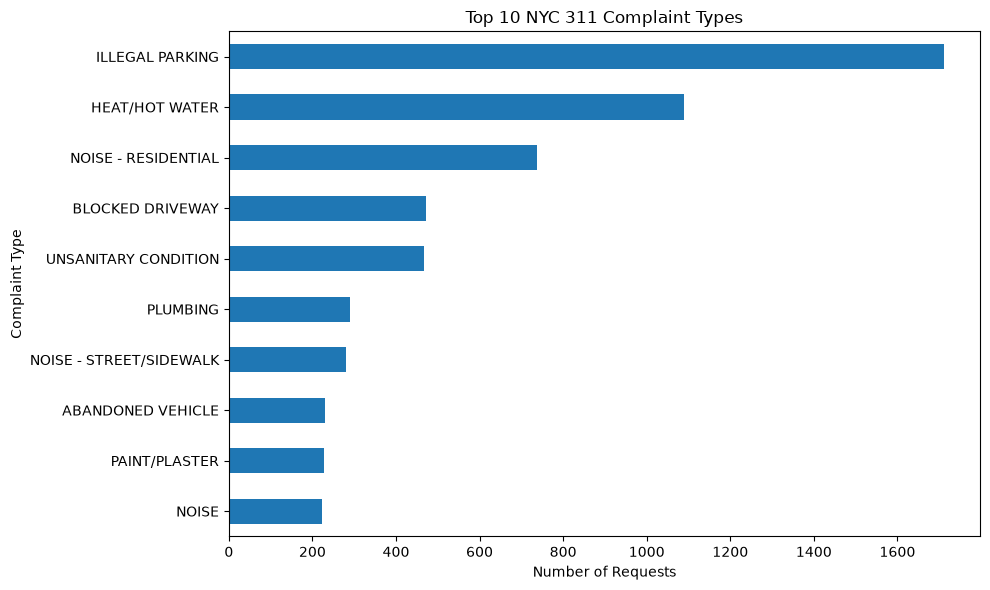

In [8]:
plt.figure(figsize=(10, 6))

complaint_counts.plot(kind="barh")

plt.title("Top 10 NYC 311 Complaint Types")
plt.xlabel("Number of Requests")
plt.ylabel("Complaint Type")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "top_10_complaint_types.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Illegal Parking is the most frequent complaint category in the 10,000-record dataset, followed by Heat/Hot Water and Noise - Residential.

### Requests by borough

In [9]:
borough_counts = df["borough"].value_counts()
borough_counts

borough
BROOKLYN         3219
MANHATTAN        2251
QUEENS           2191
BRONX            1982
STATEN ISLAND     341
UNSPECIFIED        16
Name: count, dtype: int64

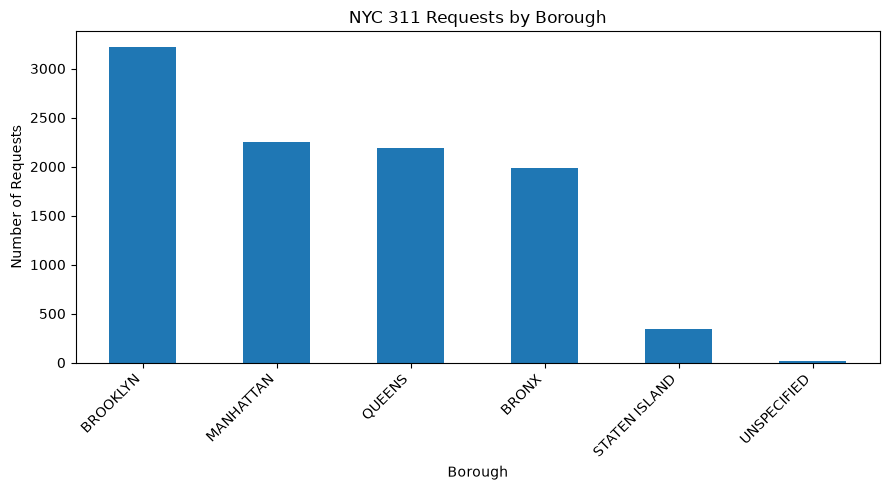

In [10]:
plt.figure(figsize=(9, 5))

borough_counts.plot(kind="bar")

plt.title("NYC 311 Requests by Borough")
plt.xlabel("Borough")
plt.ylabel("Number of Requests")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "requests_by_borough.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Brooklyn accounts for the largest share of requests, followed by Manhattan  and Queens .

### Requests by status

In [11]:
status_counts = df["status"].value_counts()

status_counts

status
CLOSED         4370
OPEN           3369
IN PROGRESS    2238
ASSIGNED         23
Name: count, dtype: int64

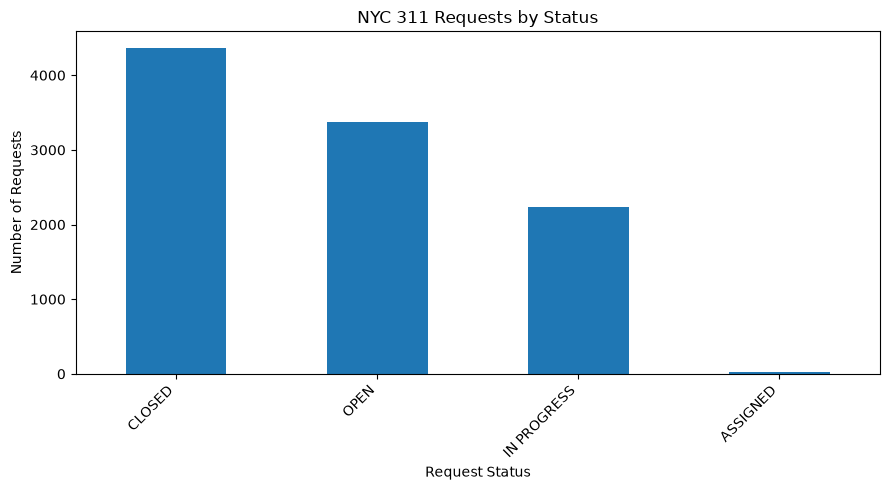

In [12]:

plt.figure(figsize=(9, 5))

status_counts.plot(kind="bar")

plt.title("NYC 311 Requests by Status")
plt.xlabel("Request Status")
plt.ylabel("Number of Requests")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "requests_by_status.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


43.7% of requests are marked as CLOSED, while 33.69% remain OPEN and 22.38% are IN PROGRESS. Only 23 requests are marked as ASSIGNED.

# Borough Analysis

In [13]:
borough_analysis = (
    df.groupby("borough")
    .agg(total_requests=("unique_key", "count"), closed_requests=("status", lambda x: (x == "CLOSED").sum())))

borough_analysis["closure_rate_pct"] = (
    borough_analysis["closed_requests"]
    / borough_analysis["total_requests"] * 100
).round(2)

borough_analysis

,total_requests,closed_requests,closure_rate_pct
borough,,,
BRONX,1982,753,37.99
BROOKLYN,3219,1484,46.10
MANHATTAN,2251,903,40.12
QUEENS,2191,1107,50.52
STATEN ISLAND,341,122,35.78
UNSPECIFIED,16,1,6.25


The borough-level aggregation shows differences in the proportion of requests marked as CLOSED. Queens has the highest closure rate (50.52%), while Staten Island has the lowest (35.78%)

### request statuses across boroughs

In [14]:
borough_status_pivot = pd.pivot_table(
    df,
    index="borough",
    columns="status",
    values="unique_key",
    aggfunc="count",
    fill_value=0
)

borough_status_pivot

status,ASSIGNED,CLOSED,IN PROGRESS,OPEN
borough,,,,
BRONX,0,753,255,974
BROOKLYN,10,1484,755,970
MANHATTAN,5,903,493,850
QUEENS,8,1107,579,497
STATEN ISLAND,0,122,141,78
UNSPECIFIED,0,1,15,0


The pivot table reveals differences in request-status distribution across boroughs. Brooklyn has the highest number of CLOSED requests, while the Bronx has the highest number of OPEN requests.

### closed status to 0,1

In [15]:
df["is_closed"] = np.where(
    df["status"] == "CLOSED",
    1,
    0
)


In [16]:
print(df["is_closed"].value_counts())

is_closed
0    5630
1    4370
Name: count, dtype: int64


### Calculate request duration

In [17]:
df["resolution_hours"] = np.where(
    df["closed_date"].notna(),
    (df["closed_date"] - df["created_date"]).dt.total_seconds() / 3600,
    np.nan
)

print(df["resolution_hours"].describe())

count    4680.000000
mean        1.977943
std         2.489862
min        -0.008889
25%         0.397361
50%         1.068750
75%         2.533750
max        18.416667
Name: resolution_hours, dtype: float64


Request counts by borough and status

In [18]:
import sqlite3

DB_PATH = PROJECT_ROOT / "outputs" / "nyc_311.db"


In [19]:
with sqlite3.connect(DB_PATH) as conn:
    df.to_sql(
        "nyc_311_requests",
        conn,
        if_exists="replace",
        index=False
    )

In [20]:
sql_query = """
    SELECT
        borough,
        status,
        COUNT(*) AS total_requests
    FROM nyc_311_requests
    GROUP BY borough, status
    ORDER BY borough, total_requests DESC;
    """


In [21]:
sql_result = pd.read_sql_query(sql_query, conn)

sql_result.to_csv(
    PROJECT_ROOT / "outputs" / "reports" / "borough_status_sql.csv",
    index=False
)

In [22]:
sql_result

,borough,status,total_requests
0,BRONX,OPEN,974
1,BRONX,CLOSED,753
2,BRONX,IN PROGRESS,255
3,BROOKLYN,CLOSED,1484
4,BROOKLYN,OPEN,970
5,BROOKLYN,IN PROGRESS,755
6,BROOKLYN,ASSIGNED,10
7,MANHATTAN,CLOSED,903
8,MANHATTAN,OPEN,850
9,MANHATTAN,IN PROGRESS,493


### Prepare completion-time regression datas

In [23]:
model_df = df.copy()

In [24]:
model_df["created_date"] = pd.to_datetime(
    model_df["created_date"], errors="coerce"
)
model_df["closed_date"] = pd.to_datetime(
    model_df["closed_date"], errors="coerce"
)

In [25]:
model_df["completion_hours"] = (
    model_df["closed_date"] - model_df["created_date"]
).dt.total_seconds() / 3600


In [26]:
valid_mask = (
    model_df["closed_date"].notna()
    & model_df["completion_hours"].notna()
    & (model_df["completion_hours"] >= 0)
)

In [27]:
regression_df = model_df.loc[valid_mask].copy()


In [28]:
print("Original records:", len(model_df))
print("Records with closure date:", model_df["closed_date"].notna().sum())
print("Negative durations:", (model_df["completion_hours"] < 0).sum())
print("Zero-hour durations:", (model_df["completion_hours"] == 0).sum())
print("Eligible regression records:", len(regression_df))


Original records: 10000
Records with closure date: 4680
Negative durations: 12
Zero-hour durations: 302
Eligible regression records: 4668


In [29]:
print("\nCompletion time distribution:")
print(regression_df["completion_hours"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90]
))


Completion time distribution:
count    4668.000000
mean        1.983038
std         2.491029
min         0.000000
25%         0.399931
50%         1.072361
75%         2.537778
90%         5.076167
max        18.416667
Name: completion_hours, dtype: float64


In [30]:
output_dir = PROJECT_ROOT / "Data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "nyc_311_regression.csv"
regression_df.to_csv(output_path, index=False)